# 04 - Phase 1 results: state-of-the-art infill on PMI-like data

Figures for the phase-1 report. Every figure is also written to `results/figures/` as PNG (200 dpi) and PDF.

**Setup.** 30 time steps × 6 PMI-like products from SDO/HMI 720 s series (2024-05-09 08:36 → 2024-05-10 02:00 TAI,
36-min cadence, AR 13664), Fourier-downsampled to 2048² at 1.008″/px. Each product sequence is compressed with
CCSDS 122 (lossless, 256 blocks/segment), packetized as CCSDS 133 (1024 B packets) and sent through a
Gilbert–Elliott channel (1 % mean packet loss, mean burst 5 packets).

**Methods.** Spatial: **FSE** (frequency selective extrapolation, Seiler & Kaup 2010). Temporal: **DMVE**
(decoder motion vector estimation, Zhang et al. 2000; 3 past + 1 future reference). References: biharmonic
inpainting (spatial) and previous-frame copy (temporal). All methods fill `mask_lost`, the full inverse-DWT
support of the lost blocks.

Run `scripts/run_infill_eval.py --name pmi_1as_ge1` first (creates the CSV and the trials).

In [1]:
%matplotlib inline
import csv
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from hmi_infill import prep
from hmi_infill.infill import DMVE, FSE, Biharmonic, InfillInput, PreviousFrame, run
from hmi_infill.pipeline import Trial

RUN = "pmi_1as_ge1"
ROOT = Path("..")
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

PRODUCTS = ["icnt", "blos", "vlos", "bmag", "binc", "bazi"]
LABEL = {"icnt": "Continuum intensity", "blos": "LOS magnetic field", "vlos": "LOS velocity",
         "bmag": "Field strength", "binc": "Inclination", "bazi": "Azimuth"}
UNIT = {"icnt": "DN/s", "blos": "G", "vlos": "m/s", "bmag": "G", "binc": "deg", "bazi": "deg"}
SCALE = prep.PRODUCT_SCALE

# Fixed method order and colours (validated categorical palette, slots 1-4).
METHODS = ["fse", "dmve", "biharmonic", "previous_frame"]
MNAME = {"fse": "FSE (spatial)", "dmve": "DMVE (temporal)", "biharmonic": "Biharmonic", "previous_frame": "Previous frame"}
COLOR = {"fse": "#2a78d6", "dmve": "#eb6834", "biharmonic": "#1baf7a", "previous_frame": "#eda100"}
MAKE = {"fse": FSE, "dmve": DMVE, "biharmonic": Biharmonic, "previous_frame": PreviousFrame}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", dpi=200, bbox_inches="tight")
    print("saved", FIG / f"{name}.png")

rows = list(csv.DictReader(open(ROOT / "results" / f"{RUN}.csv")))
for r in rows:
    r["frame"] = int(r["frame"])
    for k in ("rmse", "mae", "psnr", "ssim_bbox", "std_ratio", "seconds", "pixels_frac", "bias"):
        r[k] = float(r[k])

def trials_of(product):
    return [Trial.load(d) for d in sorted((ROOT / "trials" / RUN / product).glob("frame_*"))]

def geometry(trial):
    _, h = prep.load_fits(ROOT / trial.meta["source"] if not Path(trial.meta["source"]).is_absolute() else trial.meta["source"])
    x0, y0, r = prep.disk_geometry(h)
    yy, xx = np.indices(trial.truth.shape)
    return np.hypot(xx - x0, yy - y0) / r

print(len(rows), "result rows")

647 result rows


## 1. Data set: the six PMI-like products

saved ../results/figures/fig01_products.png


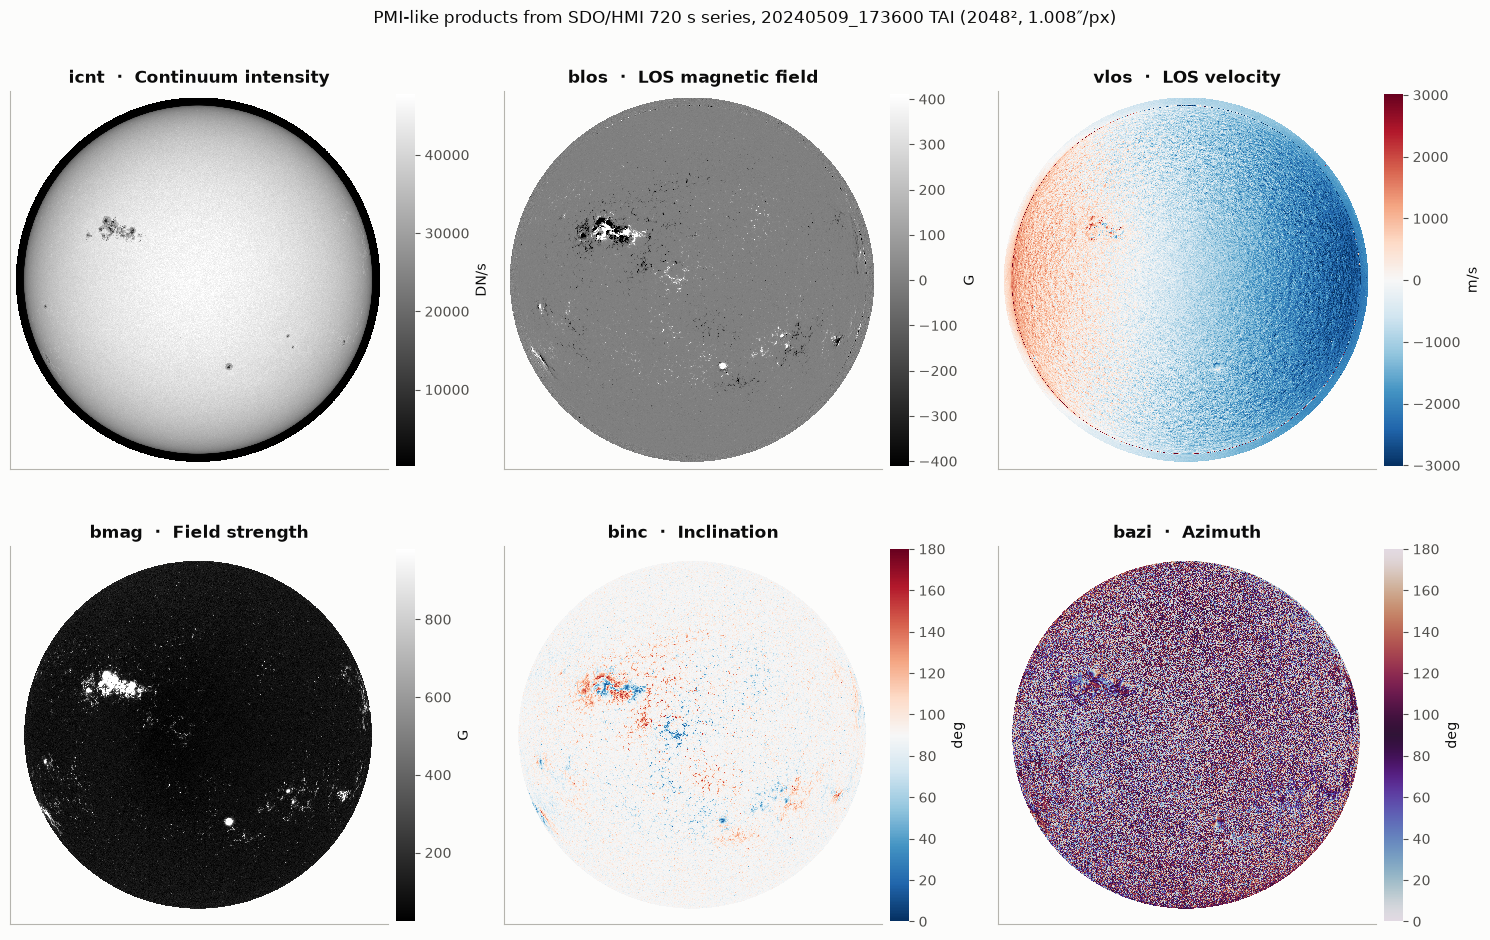

In [2]:
T_SHOW = 15
STYLE = {  # colormap, symmetric limits
    "icnt": ("gray", False), "blos": ("gray", True), "vlos": ("RdBu_r", True),
    "bmag": ("gray", False), "binc": ("RdBu_r", "90"), "bazi": ("twilight", "cyclic"),
}
fig, axs = plt.subplots(2, 3, figsize=(15, 9.6))
for ax, p in zip(axs.ravel(), PRODUCTS):
    f = sorted((ROOT / "data/raw/pmi_like_1as" / p).glob("*.fits"))[T_SHOW]
    d, h = prep.load_fits(f)
    cmap, sym = STYLE[p]
    if sym is True:
        v = np.nanpercentile(np.abs(d), 99.5); lim = (-v, v)
    elif sym == "90":
        lim = (0, 180)
    elif sym == "cyclic":
        lim = (0, 180)
    else:
        lim = tuple(np.nanpercentile(d, [0.5, 99.5]))
    im = ax.imshow(d, origin="lower", cmap=cmap, vmin=lim[0], vmax=lim[1], interpolation="nearest")
    ax.set_title(f"{p}  ·  {LABEL[p]}"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02); cb.set_label(UNIT[p]); cb.outline.set_visible(False)
fig.suptitle(f"PMI-like products from SDO/HMI 720 s series, {f.stem.split('_', 1)[1]} TAI (2048², 1.008″/px)", y=0.995)
fig.tight_layout()
save(fig, "fig01_products")

## 2. Simulated packet loss

Per-product loss statistics over the 30 frames, then one damaged frame in detail.

In [3]:
stats = {}
for p in PRODUCTS:
    ms = [json_meta for json_meta in (t.meta for t in trials_of(p))]
    stats[p] = dict(
        bpp=np.mean([m["bits_per_pixel"] for m in ms]),
        packets=np.mean([m["n_packets"] for m in ms]),
        loss=np.mean([m["packet_loss_rate"] for m in ms]),
        frames_hit=sum(m["blocks_lost"] > 0 for m in ms),
        seg_lost=sum(m["segments_lost"] for m in ms), seg_trunc=sum(m["segments_truncated"] for m in ms),
        core=np.mean([m["pixels_core_fraction"] for m in ms]), affected=np.mean([m["pixels_lost_fraction"] for m in ms]),
    )
print(f"{'product':8s} {'bpp':>6s} {'packets/frame':>13s} {'pkt loss':>8s} {'frames hit':>10s} {'seg lost':>8s} {'seg trunc':>9s} {'core px':>8s} {'affected px':>11s}")
for p, s in stats.items():
    print(f"{p:8s} {s['bpp']:6.2f} {s['packets']:13.0f} {s['loss']:8.2%} {s['frames_hit']:10d} {s['seg_lost']:8d} {s['seg_trunc']:9d} {s['core']:8.2%} {s['affected']:11.2%}")

product     bpp packets/frame pkt loss frames hit seg lost seg trunc  core px affected px
icnt       9.19          4896    1.14%         28       94       296    1.22%       6.27%
blos       7.23          3879    0.90%         24       75       192    0.98%       5.12%
vlos       9.22          4894    0.95%         27       65       273    0.85%       4.62%
bmag       6.44          3479    1.06%         28       79       180    1.03%       5.20%
binc       8.27          4417    1.01%         29       86       235    1.12%       5.20%
bazi      10.78          5715    0.97%         27       74       325    0.96%       5.21%


saved ../results/figures/fig02_loss_example.png


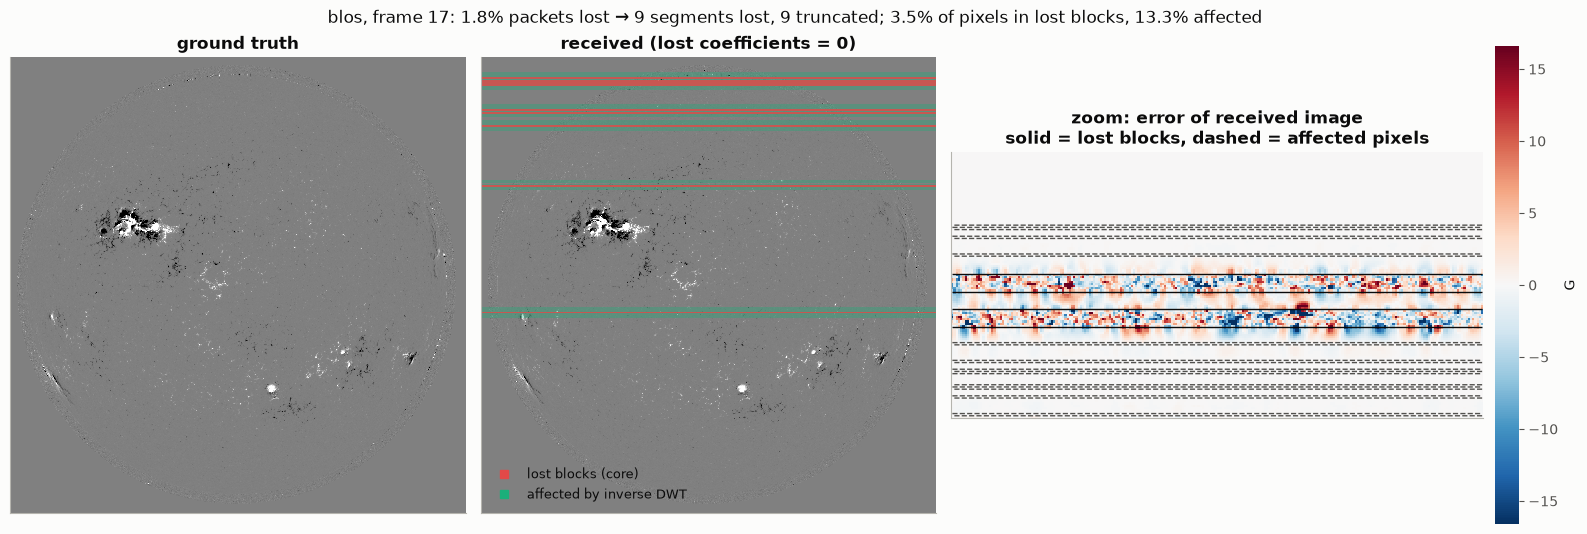

In [4]:
from matplotlib.colors import ListedColormap
P = "blos"
tr = trials_of(P)
k = int(np.argmax([t.meta["blocks_lost"] for t in tr]))
t = tr[k]
sc = SCALE[P]
fig, axs = plt.subplots(1, 3, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1, 1, 1.25]})
v = 600
for ax, img, ttl in ((axs[0], t.truth, "ground truth"), (axs[1], t.damaged, "received (lost coefficients = 0)")):
    ax.imshow(img * sc, origin="lower", cmap="gray", vmin=-v, vmax=v, interpolation="nearest")
    ax.set_title(ttl); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axs[1].imshow(t.mask_lost, origin="lower", cmap=ListedColormap([(0, 0, 0, 0), "#1baf7a"]), alpha=0.35, interpolation="nearest")
axs[1].imshow(t.mask_core, origin="lower", cmap=ListedColormap([(0, 0, 0, 0), "#e34948"]), alpha=0.8, interpolation="nearest")
# zoom on one lost strip: error of the damaged decode
ys = np.flatnonzero(t.mask_core.any(1)); yc = int(np.median(ys))
xs = np.flatnonzero(t.mask_core[yc] & t.valid[yc]); xc = int(np.median(xs)) if xs.size else 1024
z = np.s_[max(yc - 60, 0):yc + 60, max(xc - 120, 0):xc + 120]
err = np.where(t.valid, (t.damaged - t.truth) * sc, 0)[z]
e = np.percentile(np.abs(err), 99.5)
im = axs[2].imshow(err, origin="lower", cmap="RdBu_r", vmin=-e, vmax=e, interpolation="nearest")
axs[2].contour(t.mask_core[z], levels=[0.5], colors="#0b0b0b", linewidths=1)
axs[2].contour(t.mask_lost[z], levels=[0.5], colors="#52514e", linewidths=1, linestyles="--")
axs[2].set_title("zoom: error of received image\nsolid = lost blocks, dashed = affected pixels"); axs[2].set_xticks([]); axs[2].set_yticks([]); axs[2].grid(False)
cb = plt.colorbar(im, ax=axs[2], fraction=0.046, pad=0.02); cb.set_label("G"); cb.outline.set_visible(False)
axs[1].plot([], [], "s", color="#e34948", label="lost blocks (core)"); axs[1].plot([], [], "s", color="#1baf7a", label="affected by inverse DWT")
axs[1].legend(loc="lower left", fontsize=9)
m = t.meta
fig.suptitle(f"{P}, frame {k}: {m['packet_loss_rate']:.1%} packets lost → {m['segments_lost']} segments lost, "
             f"{m['segments_truncated']} truncated; {m['pixels_core_fraction']:.1%} of pixels in lost blocks, "
             f"{m['pixels_lost_fraction']:.1%} affected")
fig.tight_layout()
save(fig, "fig02_loss_example")

## 3. Accuracy per product

Median RMSE relative to biharmonic inpainting (below 1 = better than the spatial reference). One axis, one ratio, so all products share a scale.

saved ../results/figures/fig03_relative_rmse.png
product       FSE (spatial)    DMVE (temporal)         Biharmonic     Previous frame   (median RMSE, physical units)
icnt               2941.063           1028.851           1141.261           1323.653   DN/s
blos                 34.899             31.264             33.092             42.414   G
vlos                399.885            435.267            414.531            524.028   m/s
bmag                 52.479             48.004             49.395             65.086   G
binc                  7.974              7.284              8.116             10.017   deg
bazi                 51.384             50.864             50.721             50.433   deg


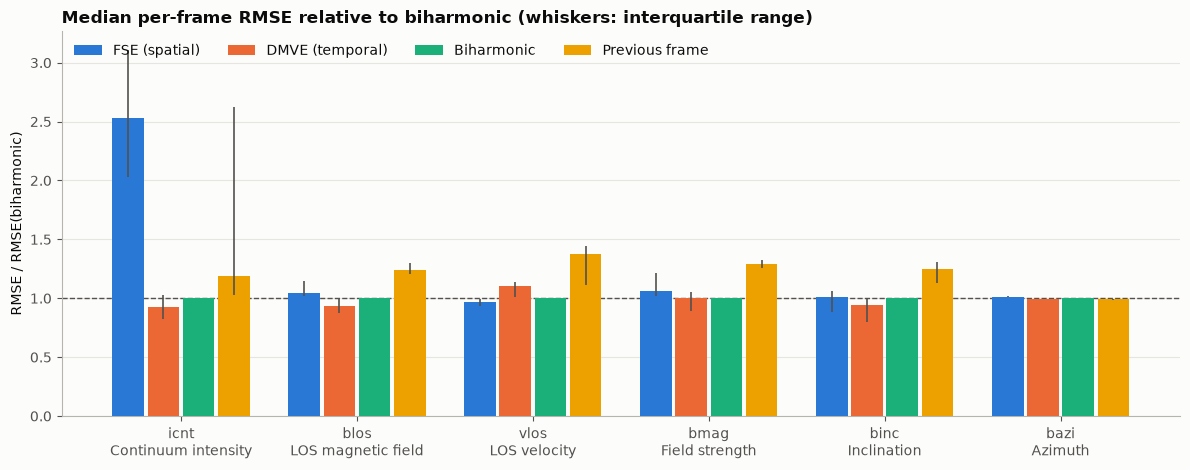

In [5]:
by = defaultdict(lambda: defaultdict(dict))      # product -> frame -> method -> row
for r in rows:
    by[r["product"]][r["frame"]][r["method"]] = r

def rel(p, m):
    v = [f[m]["rmse"] / f["biharmonic"]["rmse"] for f in by[p].values() if m in f]
    return np.median(v), np.percentile(v, 25), np.percentile(v, 75)

fig, ax = plt.subplots(figsize=(12, 4.8))
w = 0.2
x = np.arange(len(PRODUCTS))
for j, m in enumerate(METHODS):
    med = np.array([rel(p, m) for p in PRODUCTS])
    xs = x + (j - 1.5) * w
    ax.bar(xs, med[:, 0], w * 0.9, color=COLOR[m], label=MNAME[m], zorder=3)
    ax.vlines(xs, med[:, 1], med[:, 2], color="#52514e", linewidth=1.2, zorder=4)
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--", zorder=2)
ax.set_xticks(x, [f"{p}\n{LABEL[p]}" for p in PRODUCTS])
ax.set_ylabel("RMSE / RMSE(biharmonic)")
ax.set_ylim(0, max(2.0, ax.get_ylim()[1]))
ax.grid(axis="x", visible=False)
ax.legend(ncol=4, loc="upper left")
ax.set_title("Median per-frame RMSE relative to biharmonic (whiskers: interquartile range)", loc="left")
fig.tight_layout()
save(fig, "fig03_relative_rmse")

print(f"{'product':8s} " + " ".join(f"{MNAME[m]:>18s}" for m in METHODS) + "   (median RMSE, physical units)")
for p in PRODUCTS:
    print(f"{p:8s} " + " ".join(f"{np.median([f[m]['rmse'] for f in by[p].values() if m in f]):18.3f}" for m in METHODS) + f"   {UNIT[p]}")

### Per-frame RMSE distributions

Small multiples: each product on its own axis in physical units.

saved ../results/figures/fig04_rmse_per_frame.png


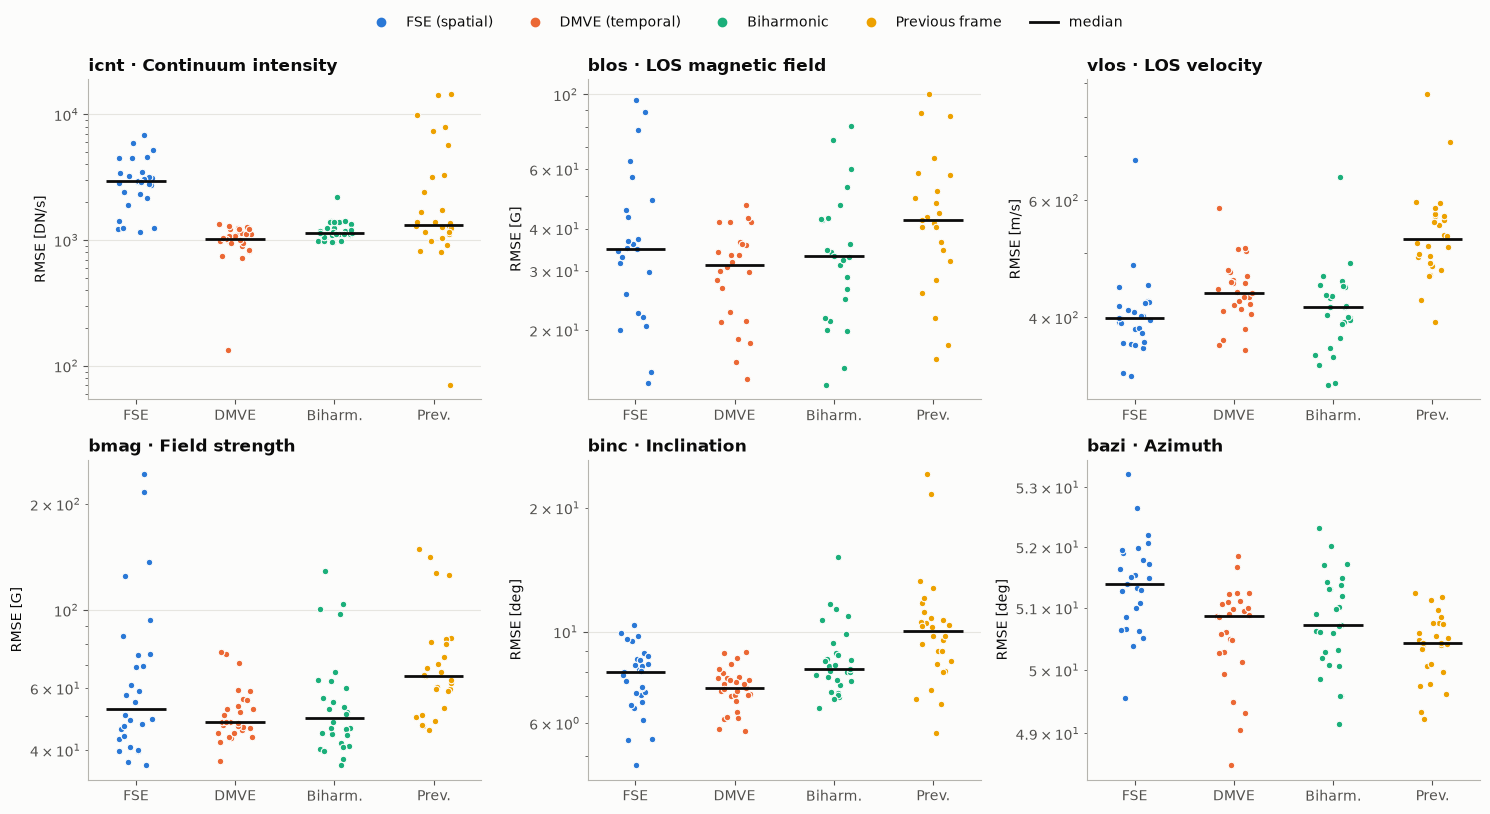

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
rng = np.random.default_rng(0)
for ax, p in zip(axs.ravel(), PRODUCTS):
    for j, m in enumerate(METHODS):
        v = np.array([f[m]["rmse"] for f in by[p].values() if m in f])
        ax.scatter(j + rng.uniform(-0.18, 0.18, v.size), v, s=22, color=COLOR[m], edgecolor="#fcfcfb", linewidth=0.8, zorder=3)
        ax.hlines(np.median(v), j - 0.3, j + 0.3, color="#0b0b0b", linewidth=2, zorder=4)
    ax.set_xticks(range(len(METHODS)), ["FSE", "DMVE", "Biharm.", "Prev."])
    ax.set_yscale("log"); ax.set_ylabel(f"RMSE [{UNIT[p]}]"); ax.set_title(f"{p} · {LABEL[p]}", loc="left")
    ax.grid(axis="x", visible=False)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=COLOR[m], label=MNAME[m]) for m in METHODS]
handles.append(plt.Line2D([], [], color="#0b0b0b", label="median"))
fig.legend(handles=handles, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "fig04_rmse_per_frame")

### Which method wins each frame

saved ../results/figures/fig05_wins.png


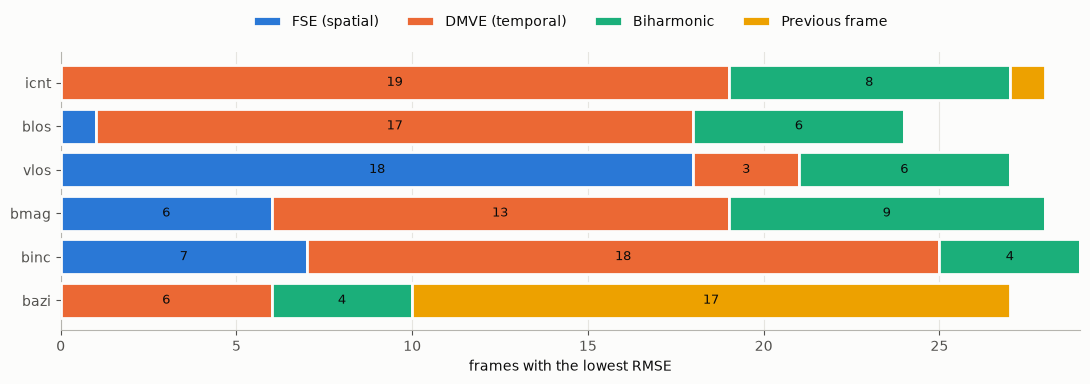

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
left = np.zeros(len(PRODUCTS))
for m in METHODS:
    cnt = np.array([Counter(min(f, key=lambda q: f[q]["rmse"]) for f in by[p].values())[m] for p in PRODUCTS])
    ax.barh(PRODUCTS, cnt, left=left, color=COLOR[m], label=MNAME[m], edgecolor="#fcfcfb", linewidth=2, zorder=3)
    for y, (l, c) in enumerate(zip(left, cnt)):
        if c >= 3:
            ax.text(l + c / 2, y, str(c), ha="center", va="center", fontsize=9, color="#0b0b0b")
    left += cnt
ax.invert_yaxis(); ax.set_xlabel("frames with the lowest RMSE"); ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.18))
fig.tight_layout()
save(fig, "fig05_wins")

## 4. Where temporal information helps: centre-to-limb dependence

At a 36-min cadence granulation (lifetime ≈ 10 min) is completely renewed between frames, while sunspots, active
regions, limb darkening and the limb itself persist. The error as a function of disk position shows the
consequence. (Methods re-run here on every third damaged frame.)

In [8]:
EDGES = np.array([0, 0.5, 0.7, 0.85, 0.93, 0.97, 1.0])
def radial(p, methods=("fse", "dmve", "biharmonic"), every=3):
    tr = trials_of(p)
    rho = geometry(tr[0])
    acc = {m: np.zeros((len(EDGES) - 1, 2)) for m in methods}
    for i, t in enumerate(tr):
        if t.meta["blocks_lost"] == 0 or i % every:
            continue
        x = InfillInput.from_trials(tr, i, n_past=3, n_future=1, mask="mask_lost")
        mm = x.mask & t.valid
        for m in methods:
            e2 = ((run(MAKE[m](), x) - t.truth) * SCALE[p]) ** 2
            for b in range(len(EDGES) - 1):
                sel = mm & (rho >= EDGES[b]) & (rho < EDGES[b + 1])
                acc[m][b] += (e2[sel].sum(), sel.sum())
    return {m: np.sqrt(a[:, 0] / np.maximum(a[:, 1], 1)) for m, a in acc.items()}, acc[methods[0]][:, 1]

rad = {p: radial(p) for p in ("icnt", "blos", "vlos")}

saved ../results/figures/fig06_centre_to_limb.png
icnt pixels per bin: [451444 516278 400944 243578 124124  87690]
   FSE (spatial)       2027.3    2128.9    1087.7    1477.5    2288.8    4145.2
   DMVE (temporal)     1515.1    1322.6     967.1     719.8     513.6     321.0
   Biharmonic          1357.9    1298.6     836.0     629.1     474.1    1832.6
blos pixels per bin: [277761 304407 295627 180503  97077  67808]
   FSE (spatial)         31.1      44.6      22.9      20.3      11.8      32.4
   DMVE (temporal)       24.4      27.2      17.8      12.8       9.5      19.4
   Biharmonic            29.5      38.6      20.8      14.7      10.8      29.0
vlos pixels per bin: [379739 278296 272130 148188  83246  57719]
   FSE (spatial)        305.5     409.6     420.2     381.2     327.0     349.9
   DMVE (temporal)      369.8     490.7     509.1     460.1     390.4     312.7
   Biharmonic           300.1     402.9     418.3     371.9     343.6     372.3


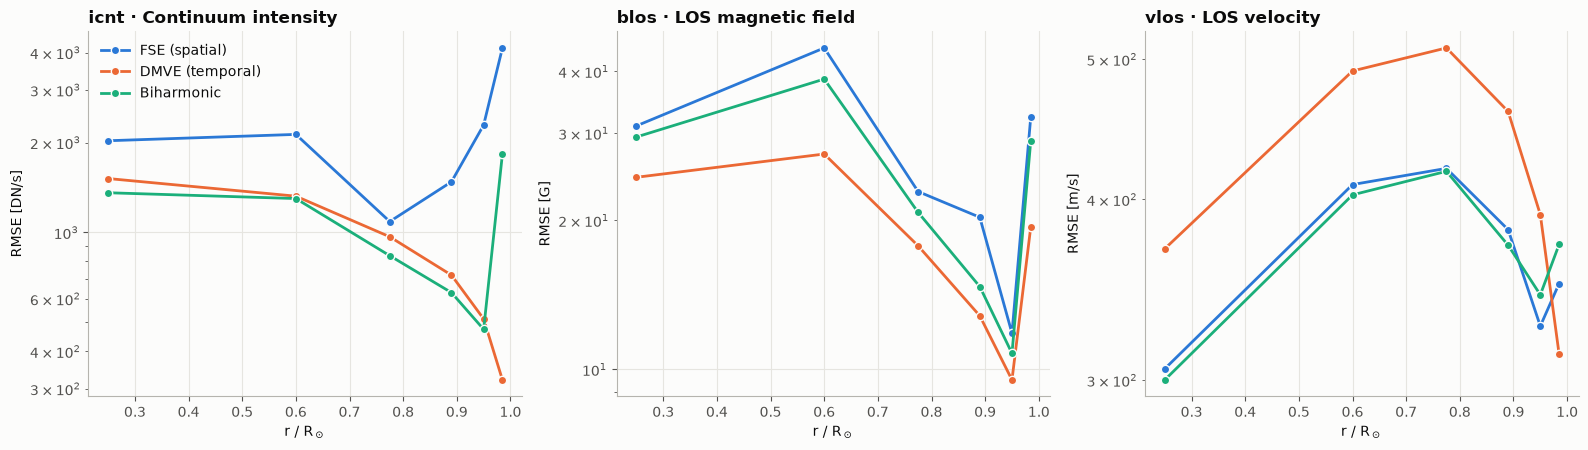

In [9]:
centres = (EDGES[:-1] + EDGES[1:]) / 2
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (p, (res, npx)) in zip(axs, rad.items()):
    for m, v in res.items():
        ax.plot(centres, v, "-o", color=COLOR[m], markersize=6, markeredgecolor="#fcfcfb", label=MNAME[m])
    ax.set_yscale("log"); ax.set_xlabel("r / R$_\\odot$"); ax.set_ylabel(f"RMSE [{UNIT[p]}]")
    ax.set_title(f"{p} · {LABEL[p]}", loc="left")
axs[0].legend(loc="upper left")
fig.tight_layout()
save(fig, "fig06_centre_to_limb")
for p, (res, npx) in rad.items():
    print(p, "pixels per bin:", npx.astype(int))
    for m, v in res.items():
        print(f"   {MNAME[m]:16s}", " ".join(f"{a:9.1f}" for a in v))

## 5. Azimuth: error vs transverse field strength

The azimuth is only measured where the transverse field B_T is strong; elsewhere it is noise, and any method
scores ≈ 52° (the RMS of a uniformly random axial error). Restricting the evaluation to strong-field pixels shows
the real differences.

saved ../results/figures/fig07_azimuth_vs_bt.png
pixels: [1558256  519844   42339   22657   11231    6046    2934]
FSE (spatial)      51.6   50.6   42.6   39.7   37.1   35.4   32.6
DMVE (temporal)    50.9   49.4   36.6   32.0   27.6   23.8   19.4
Biharmonic         50.9   49.2   34.7   30.5   27.3   25.1   22.0
Previous frame     50.6   48.9   35.9   32.5   29.3   27.6   26.2


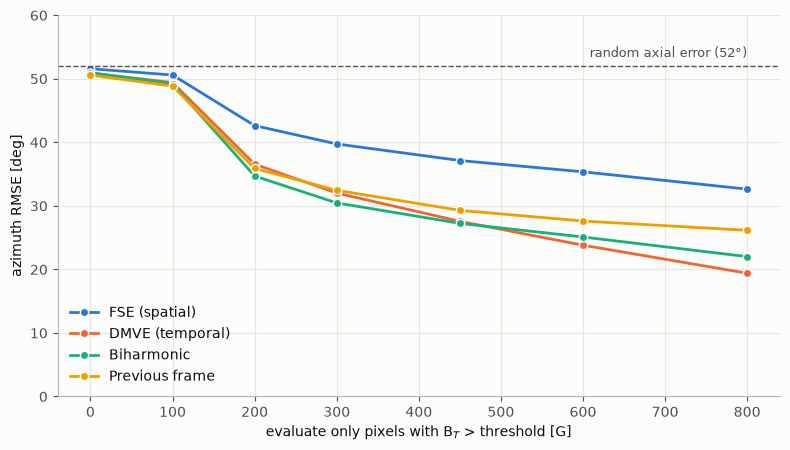

In [10]:
THR = [0, 100, 200, 300, 450, 600, 800]
az, bm, bi = trials_of("bazi"), trials_of("bmag"), trials_of("binc")
acc = {m: np.zeros((len(THR), 2)) for m in METHODS}
for i, t in enumerate(az):
    if t.meta["blocks_lost"] == 0 or i == 0 or i % 2:
        continue
    bt = bm[i].truth * SCALE["bmag"] * np.abs(np.sin(np.deg2rad(bi[i].truth * SCALE["binc"])))
    x = InfillInput.from_trials(az, i, n_past=3, n_future=1, mask="mask_lost")
    for m in METHODS:
        e = (run(MAKE[m](), x) - t.truth) * SCALE["bazi"]
        e = (e + 90) % 180 - 90
        for j, th in enumerate(THR):
            sel = x.mask & t.valid & (bt > th)
            acc[m][j] += ((e[sel] ** 2).sum(), sel.sum())
fig, ax = plt.subplots(figsize=(8, 4.6))
for m in METHODS:
    ax.plot(THR, np.sqrt(acc[m][:, 0] / np.maximum(acc[m][:, 1], 1)), "-o", color=COLOR[m], markersize=6,
            markeredgecolor="#fcfcfb", label=MNAME[m])
ax.axhline(180 / np.sqrt(12), color="#52514e", linestyle="--", linewidth=1)
ax.text(THR[-1], 180 / np.sqrt(12) + 1, "random axial error (52°)", ha="right", va="bottom", fontsize=9, color="#52514e")
ax.set_xlabel("evaluate only pixels with B$_T$ > threshold [G]"); ax.set_ylabel("azimuth RMSE [deg]")
ax.set_ylim(0, 60); ax.legend(loc="lower left")
fig.tight_layout()
save(fig, "fig07_azimuth_vs_bt")
print("pixels:", acc["fse"][:, 1].astype(int))
for m in METHODS:
    print(f"{MNAME[m]:16s}", " ".join(f"{a:6.1f}" for a in np.sqrt(acc[m][:, 0] / np.maximum(acc[m][:, 1], 1))))

## 6. Texture preservation

Standard deviation of the filled region divided by that of the truth (1 = right amount of structure, < 1 = too smooth).

saved ../results/figures/fig08_std_ratio.png


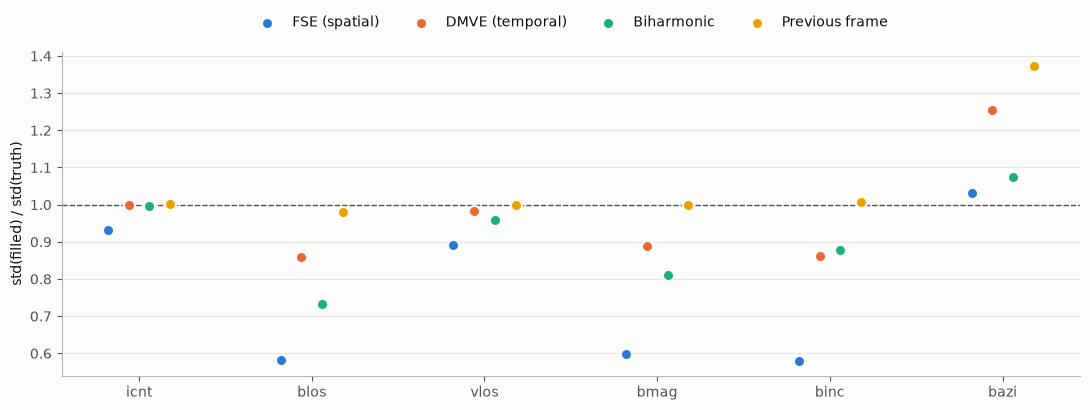

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for j, m in enumerate(METHODS):
    med = [np.median([f[m]["std_ratio"] for f in by[p].values() if m in f]) for p in PRODUCTS]
    ax.scatter(np.arange(len(PRODUCTS)) + (j - 1.5) * 0.12, med, s=64, color=COLOR[m], edgecolor="#fcfcfb",
               linewidth=1.5, label=MNAME[m], zorder=3)
ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
ax.set_xticks(range(len(PRODUCTS)), PRODUCTS); ax.set_ylabel("std(filled) / std(truth)")
ax.grid(axis="x", visible=False); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.15))
fig.tight_layout()
save(fig, "fig08_std_ratio")

## 7. Visual comparison

Three typical situations: a loss over the active region in continuum intensity, a loss at the limb, and a loss
in the Dopplergram where temporal information is weak. Rows: images, then errors (same colour scale per row).

saved ../results/figures/fig09a_icnt_active_region.png


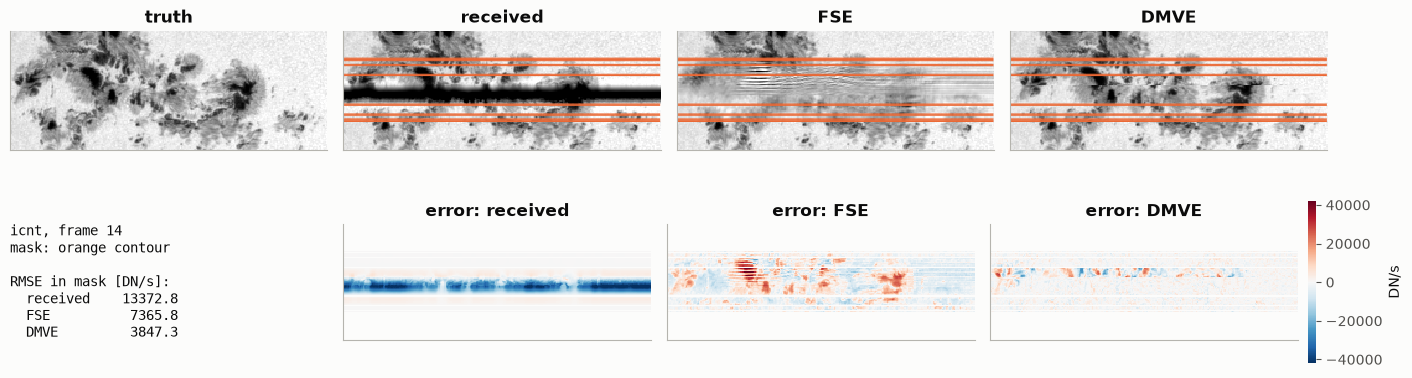

In [12]:
def pick(p, kind):
    """Frame and centre of a loss that crosses the active region / the limb / the disk centre."""
    tr = trials_of(p)
    rho = geometry(tr[0])
    best = None
    for i, t in enumerate(tr):
        if t.meta["blocks_lost"] == 0 or i == 0:
            continue
        mm = t.mask_core & t.valid
        if kind == "spot":
            score = mm & (rho < 0.9) & (t.truth < 0.6 * np.median(t.truth[t.valid]))   # spots, not the darkened limb
        elif kind == "limb":
            score = mm & (rho > 0.97)
        else:
            score = mm & (rho < 0.5)
        n = score.sum()
        if n and (best is None or n > best[0]):
            ys, xs = np.nonzero(score)
            if kind == "limb":          # centre on the outermost pixel, so the disk edge is in view
                j = int(np.argmax(rho[ys, xs])); best = (n, i, int(ys[j]), int(xs[j]))
            else:
                best = (n, i, int(np.median(ys)), int(np.median(xs)))
    return tr, best

def compare(p, kind, half=(64, 128), name=None):
    tr, (n, i, yc, xc) = pick(p, kind)
    t = tr[i]
    x = InfillInput.from_trials(tr, i, n_past=3, n_future=1, mask="mask_lost")
    outs = {m: run(MAKE[m](), x) for m in ("fse", "dmve")}
    sc = SCALE[p]
    z = np.s_[max(yc - half[0], 0):yc + half[0], max(xc - half[1], 0):xc + half[1]]
    show = [("truth", t.truth), ("received", t.damaged), ("FSE", outs["fse"]), ("DMVE", outs["dmve"])]
    vals = t.truth[z][t.valid[z]] * sc
    lo, hi = np.percentile(vals, [0.5, 99.5])
    fig, axs = plt.subplots(2, 4, figsize=(17, 4.6), gridspec_kw={"hspace": 0.18, "wspace": 0.05})
    cmap = "gray" if p != "vlos" else "RdBu_r"
    for ax, (ttl, img) in zip(axs[0], show):
        im = np.where(t.valid, img * sc, np.nan)[z]
        ax.imshow(im, origin="lower", cmap=cmap, vmin=lo, vmax=hi, interpolation="nearest")
        ax.contour(x.mask[z], levels=[0.5], colors="#eb6834" if ttl != "truth" else "none", linewidths=0.8)
        ax.set_title(ttl)
    errs = [np.where(t.valid & x.mask, (img - t.truth) * sc, np.nan)[z] for _, img in show]
    e = np.nanpercentile(np.abs(errs[1]), 99) if np.isfinite(errs[1]).any() else 1
    axs[1, 0].axis("off")
    axs[1, 0].text(0.0, 0.5, f"{p}, frame {i}\nmask: orange contour\n\nRMSE in mask [{UNIT[p]}]:\n" +
                   "\n".join(f"  {ttl:9s} {np.sqrt(np.nanmean(er ** 2)):9.1f}" for (ttl, _), er in zip(show[1:], errs[1:])),
                   va="center", family="monospace", fontsize=10)
    for ax, (ttl, _), er in zip(axs[1, 1:], show[1:], errs[1:]):
        im = ax.imshow(er, origin="lower", cmap="RdBu_r", vmin=-e, vmax=e, interpolation="nearest")
        ax.set_title(f"error: {ttl}")
    for ax in axs.ravel():
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    cb = fig.colorbar(im, ax=axs[1, 1:].tolist(), fraction=0.02, pad=0.01); cb.set_label(UNIT[p]); cb.outline.set_visible(False)
    save(fig, name)
    return fig

compare("icnt", "spot", half=(48, 128), name="fig09a_icnt_active_region");

saved ../results/figures/fig09b_icnt_limb.png


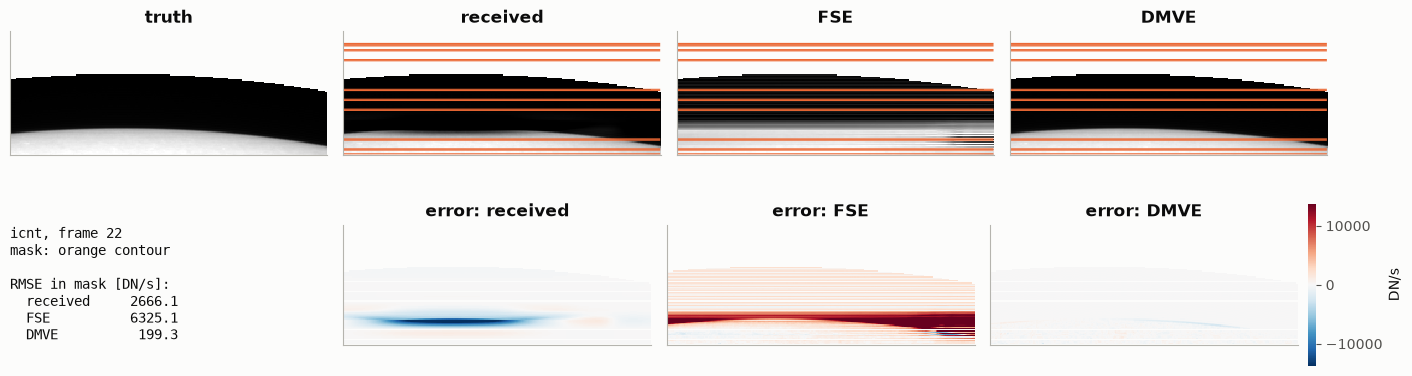

In [13]:
compare("icnt", "limb", name="fig09b_icnt_limb");

saved ../results/figures/fig09c_vlos_centre.png


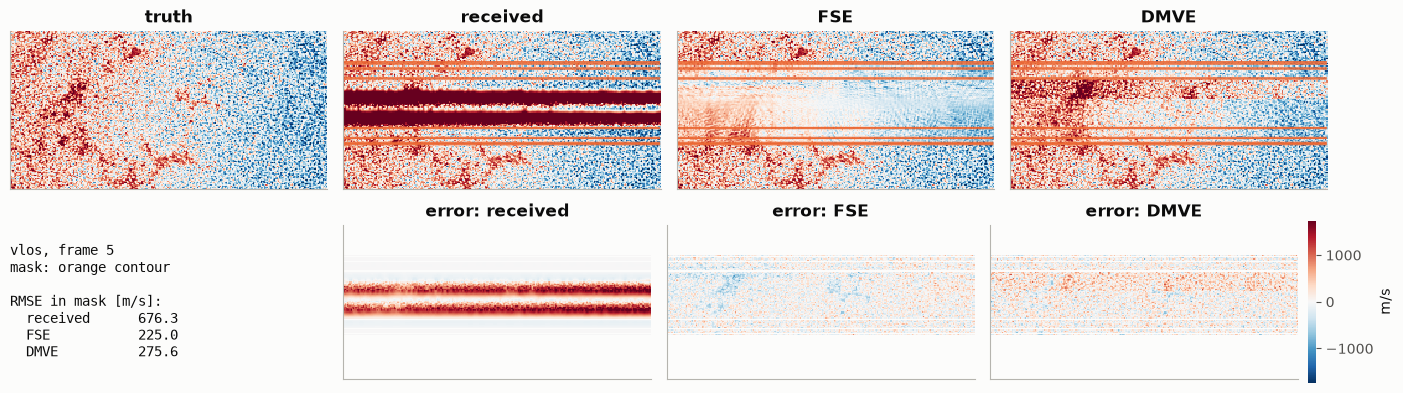

In [14]:
compare("vlos", "centre", name="fig09c_vlos_centre");

## 8. Run time

Median seconds per 2048² frame (single thread, numba-compiled kernels).

In [15]:
print(f"{'':8s} " + " ".join(f"{MNAME[m]:>18s}" for m in METHODS))
for p in PRODUCTS:
    print(f"{p:8s} " + " ".join(f"{np.median([f[m]['seconds'] for f in by[p].values() if m in f]):18.2f}" for m in METHODS))

              FSE (spatial)    DMVE (temporal)         Biharmonic     Previous frame
icnt                   4.07               2.90               1.04               0.00
blos                   3.65               2.62               0.74               0.00
vlos                   3.20               2.40               0.60               0.00
bmag                   3.23               2.46               0.60               0.00
binc                   2.99               2.33               0.62               0.00
bazi                   3.35               2.37               0.85               0.00


## Summary for the report

* **DMVE (temporal)** gives the lowest median RMSE on 4 of 6 products (icnt, blos, bmag, binc) and on the azimuth
  when the evaluation is restricted to strong-field pixels.
* **FSE (spatial)** wins on the LOS velocity, whose 5-min oscillations and convective flows decorrelate
  completely between frames 36 min apart, but fails near the limb (steep limb darkening, disk edge).
* At this cadence granulation is renewed between frames, so temporal copying is no better than a smooth spatial fill at
  disk centre; temporal information pays off on persistent structures: active regions, limb, large-scale gradients.
* Spatial fills are too smooth for the noisy magnetic products (std ratio 0.6-0.9).

These motivate the proposed improvements (limb-darkening / rotation model subtraction before FSE,
derotation prior and photometric correction for DMVE, doubled-angle infill for the azimuth) and the phase-3
spatio-temporal combination.